# Napa vintage prediction: 2000–2016, with a 2000 vs 2016 comparison

Adapted from `project3.ipynb`. The **main model learns all available vintage years from 2000 through 2016**. The final analysis compares its predictions for actual 2000 (worst) and 2016 (best) wines. A separate optional binary classifier directly distinguishes 2000 from 2016.

Uses the original model families: metadata-only logistic regression and TF-IDF descriptions + metadata logistic regression. Wine quality scores (`points`) are not the target.

In [1]:
import pandas as pd

wine_df = pd.read_csv("winemag-data-130k-v2.csv", index_col=0)
wine_df["title"].head(10)

0                    Nicosia 2013 Vulkà Bianco  (Etna)
1        Quinta dos Avidagos 2011 Avidagos Red (Douro)
2        Rainstorm 2013 Pinot Gris (Willamette Valley)
3    St. Julian 2013 Reserve Late Harvest Riesling ...
4    Sweet Cheeks 2012 Vintner's Reserve Wild Child...
5    Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...
6     Terre di Giurfo 2013 Belsito Frappato (Vittoria)
7                Trimbach 2012 Gewurztraminer (Alsace)
8    Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...
9    Jean-Baptiste Adam 2012 Les Natures Pinot Gris...
Name: title, dtype: object

In [2]:
wine_df["wine vintage"] = (
    wine_df["title"]
    .str.extract(r"\b((?:19|20)\d{2})\b", expand=False)
    .astype("Int64")
)

wine_df[["title", "wine vintage"]].head(10)

,title,wine vintage
0,Nicosia 2013 Vulkà Bianco (Etna),2013
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013
3,St. Julian 2013 Reserve Late Harvest Riesling ...,2013
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,2012
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,2011
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013
7,Trimbach 2012 Gewurztraminer (Alsace),2012
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhe...,2013
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,2012


In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

selected_vintages = list(range(2000, 2017))
napa = (wine_df.loc[
    wine_df["region_2"].eq("Napa") &
    wine_df["wine vintage"].isin(selected_vintages),
    ["title", "description", "wine vintage", "variety", "region_1"]
].dropna(subset=["title", "wine vintage"])
 .drop_duplicates(subset="title").copy())

napa["description"] = napa["description"].fillna("").astype(str)
for col in ["variety", "region_1"]:
    napa[col] = napa[col].fillna("Unknown").astype(str)
napa["wine vintage"] = napa["wine vintage"].astype(int)

# Group on exactly the same normalization used in the leakage check.
groups = napa["description"].str.strip().str.lower()
# Missing/blank descriptions are not useful for text learning.
napa = napa.loc[groups.ne("")].copy()
groups = groups.loc[napa.index]

X = napa[["variety", "region_1", "description"]].copy()
y = napa["wine vintage"].copy()
print("Counts per year:")
print(y.value_counts().sort_index().to_string())
print("Total wines:", len(y))

# Find a grouped split that includes both focal years in train and test.
splitter = GroupShuffleSplit(n_splits=100, test_size=0.2, random_state=42)
split_found = False
for train_pos, test_pos in splitter.split(X, y, groups):
    train_years = set(y.iloc[train_pos])
    test_years = set(y.iloc[test_pos])
    if {2000, 2016}.issubset(train_years) and {2000, 2016}.issubset(test_years):
        split_found = True
        break
if not split_found:
    raise ValueError("Could not find a split containing both 2000 and 2016 in training and testing. Inspect year counts.")

X_train, X_test = X.iloc[train_pos].copy(), X.iloc[test_pos].copy()
y_train, y_test = y.iloc[train_pos].copy(), y.iloc[test_pos].copy()
assert set(groups.iloc[train_pos]).isdisjoint(set(groups.iloc[test_pos]))
print("\nTrain/test counts for 2000 and 2016:")
print(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).reindex([2000, 2016]).fillna(0).astype(int))
print(f"Training: {len(X_train)} | Testing: {len(X_test)}")

Counts per year:
wine vintage
2000     52
2001     24
2002      5
2003     22
2004    169
2005    344
2006    355
2007    476
2008    505
2009    683
2010    659
2011    469
2012    893
2013    834
2014    446
2015    131
2016     68
Total wines: 6135

Train/test counts for 2000 and 2016:
              Train  Test
wine vintage             
2000             43     9
2016             56    12
Training: 4907 | Testing: 1228


## Train the original model families across 2000–2016

In [4]:
def clean_vintage_description(text):
    return re.sub(r"\b(?:18|19|20|21)\d{2}\b", " ", str(text)).lower()

metadata_cols = ["variety", "region_1"]
baseline_model = Pipeline([
    ("categories", OneHotEncoder(handle_unknown="ignore")),
    ("classifier", LogisticRegression(max_iter=1500, random_state=42))
])
baseline_model.fit(X_train[metadata_cols], y_train)

combined_vintage_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False, min_df=2, max_features=5000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata_cols)
    ])),
    ("classifier", LogisticRegression(max_iter=1500, random_state=42))
])

# Rare classes can make five-fold stratification impossible.
min_train_count = int(y_train.value_counts().min())
if min_train_count >= 2:
    folds = min(5, min_train_count)
    combined_search = GridSearchCV(
        combined_vintage_pipeline,
        {"classifier__C": [0.03, 0.1, 0.3, 1.0]},
        scoring="f1_macro",
        cv=StratifiedKFold(n_splits=folds, shuffle=True, random_state=42),
        n_jobs=-1, error_score="raise"
    )
    combined_search.fit(X_train, y_train)
    description_vintage_model = combined_search.best_estimator_
    print("Selected C:", combined_search.best_params_["classifier__C"])
else:
    # Keep all years, even if one has only a single training example.
    description_vintage_model = combined_vintage_pipeline
    description_vintage_model.fit(X_train, y_train)
    print("Skipped stratified CV because a vintage has only one training example.")

baseline_predictions = baseline_model.predict(X_test[metadata_cols])
description_vintage_predictions = description_vintage_model.predict(X_test)
print(pd.DataFrame([
    {"Model": "Metadata baseline",
     "Accuracy": accuracy_score(y_test, baseline_predictions),
     "Macro F1": f1_score(y_test, baseline_predictions, average="macro", zero_division=0)},
    {"Model": "Descriptions + metadata",
     "Accuracy": accuracy_score(y_test, description_vintage_predictions),
     "Macro F1": f1_score(y_test, description_vintage_predictions, average="macro", zero_division=0)}
]).round(3).to_string(index=False))

Selected C: 1.0
                  Model  Accuracy  Macro F1
      Metadata baseline     0.148     0.054
Descriptions + metadata     0.336     0.190


## Compare how the full 2000–2016 model predicts 2000 versus 2016

For each actual year, **exact-year recall** is the proportion correctly predicted as that year. Also compare absolute year error and the most common wrong predictions.

         Test wines  Correct  Exact-year recall  Precision  Mean absolute year error
Vintage                                                                             
2000              9        0                0.0        0.0                    11.111
2016             12        0                0.0        0.0                     2.000

Most common predictions for actual 2000 and 2016:

Actual 2000:
Predicted
2011    3
2010    2
2015    1
2014    1
2012    1
2006    1

Actual 2016:
Predicted
2014    10
2015     1
2013     1


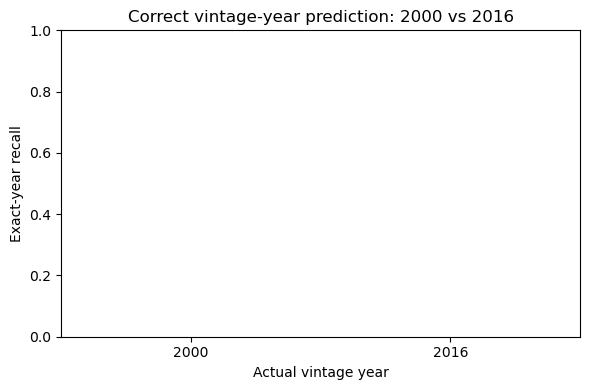

In [5]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": description_vintage_predictions
}, index=y_test.index)
results["Absolute year error"] = (results["Actual"] - results["Predicted"]).abs()
rows = []
for year in [2000, 2016]:
    subset = results.loc[results["Actual"].eq(year)]
    predicted_as_year = results["Predicted"].eq(year)
    true_year = results["Actual"].eq(year)
    precision_denom = predicted_as_year.sum()
    rows.append({
        "Vintage": year,
        "Test wines": len(subset),
        "Correct": int((subset["Predicted"] == year).sum()),
        "Exact-year recall": (subset["Predicted"] == year).mean() if len(subset) else np.nan,
        "Precision": ((predicted_as_year & true_year).sum() / precision_denom
                      if precision_denom else 0.0),
        "Mean absolute year error": subset["Absolute year error"].mean()
    })
comparison_2000_2016 = pd.DataFrame(rows).set_index("Vintage")
print(comparison_2000_2016.round(3).to_string())
print("\nMost common predictions for actual 2000 and 2016:")
for year in [2000, 2016]:
    print(f"\nActual {year}:")
    print(results.loc[results.Actual.eq(year), "Predicted"].value_counts().head(10).to_string())

ax = comparison_2000_2016["Exact-year recall"].plot(
    kind="bar", figsize=(6, 4), rot=0, ylim=(0, 1),
    title="Correct vintage-year prediction: 2000 vs 2016"
)
ax.set_ylabel("Exact-year recall")
ax.set_xlabel("Actual vintage year")
plt.tight_layout()
plt.show()

## Optional: direct binary classification of 2000 versus 2016

This is a **different question** from the full 17-year model: among wines known to come from either 2000 or 2016, can the classifier tell which one? We use the same held-out split to avoid training/test leakage.

              precision    recall  f1-score   support

        2000       0.78      0.78      0.78         9
        2016       0.83      0.83      0.83        12

    accuracy                           0.81        21
   macro avg       0.81      0.81      0.81        21
weighted avg       0.81      0.81      0.81        21



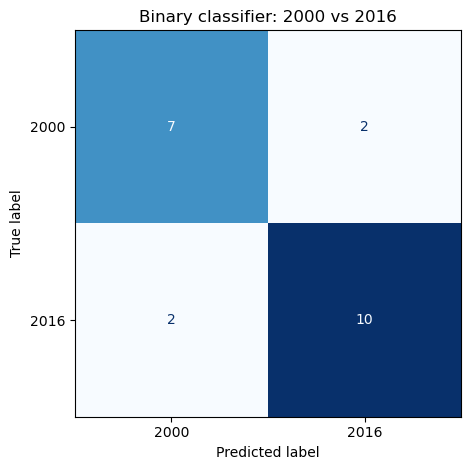

In [6]:
binary_train = y_train.isin([2000, 2016])
binary_test = y_test.isin([2000, 2016])
X_train_binary, y_train_binary = X_train.loc[binary_train], y_train.loc[binary_train]
X_test_binary, y_test_binary = X_test.loc[binary_test], y_test.loc[binary_test]
if y_train_binary.nunique() < 2 or y_test_binary.nunique() < 2:
    print("Not enough examples of both years for a binary comparison.")
else:
    binary_model = Pipeline([
        ("features", ColumnTransformer([
            ("text", TfidfVectorizer(
                preprocessor=clean_vintage_description,
                lowercase=False, min_df=1, max_features=5000
            ), "description"),
            ("metadata", OneHotEncoder(handle_unknown="ignore"), metadata_cols)
        ])),
        ("classifier", LogisticRegression(max_iter=1500, random_state=42))
    ])
    binary_model.fit(X_train_binary, y_train_binary)
    binary_predictions = binary_model.predict(X_test_binary)
    print(classification_report(y_test_binary, binary_predictions,
                                labels=[2000, 2016], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test_binary, binary_predictions, labels=[2000, 2016],
        cmap="Blues", colorbar=False
    )
    plt.title("Binary classifier: 2000 vs 2016")
    plt.tight_layout()
    plt.show()

### Interpretation caution

Different sample sizes, review wording, reviewer practices, and class imbalance can affect performance. A difference between 2000 and 2016 does **not** by itself prove vintage quality causes the difference. In the full model, report the test counts alongside exact-year recall.

In [7]:
# Eyeball error analysis: Full model (2000–2016)

full_errors = X_test.copy()

full_errors["actual_vintage"] = y_test
full_errors["predicted_vintage"] = description_vintage_predictions
full_errors["year_error"] = abs(
    full_errors["actual_vintage"] - full_errors["predicted_vintage"]
)

# Only incorrectly predicted wines
full_errors = full_errors[
    full_errors["actual_vintage"] != full_errors["predicted_vintage"]
]

# Sort by largest prediction error
full_errors = full_errors.sort_values("year_error", ascending=False)

display(full_errors[
    ["actual_vintage", "predicted_vintage",
     "year_error", "variety", "region_1", "description"]
].head(20))

full_errors.to_csv("napa_full_model_eyeball_errors.csv", index=False)

,actual_vintage,predicted_vintage,year_error,variety,region_1,description
16845,2000,2015,15,Sauvignon Blanc,Napa Valley,"Hay, cabbage and pickles in the nose? That's n..."
30872,2000,2014,14,Sauvignon Blanc,Napa Valley,"A touch of the veggies, particularly asparagus..."
64615,2000,2012,12,Cabernet Sauvignon,Napa Valley,"Quite spicy in the nose, with hints of pretty ..."
32513,2000,2011,11,Shiraz,Napa Valley,The wine starts of with intriguing bacon and e...
24349,2000,2011,11,Sauvignon Blanc,Oakville,"Aromas of glue, bacon fat and earth make for a..."
38063,2000,2011,11,Cabernet Sauvignon,Napa Valley,"Always reliable, and often a value, this vinta..."
22757,2000,2010,10,Fumé Blanc,Napa Valley,"Hardly run of the mill, this offering is just ..."
73683,2000,2010,10,Merlot,Napa County,"A success despite a certain leanness, a young ..."
43209,2004,2012,8,Cabernet Sauvignon,St. Helena,"Bright and forward in red and black cherry, pl..."
44094,2001,2009,8,Sauvignon Blanc,Napa Valley,"Smells simple, with vague notes of citrus frui..."


In [9]:
# Eyeball error analysis: Binary model (2000 vs. 2016)

binary_errors = X_test_binary.copy()

binary_errors["actual_vintage"] = y_test_binary
binary_errors["predicted_vintage"] = binary_predictions

# Only incorrectly predicted wines
binary_errors = binary_errors[
    binary_errors["actual_vintage"] != binary_errors["predicted_vintage"]
]

display(binary_errors[
    ["actual_vintage", "predicted_vintage",
     "variety", "region_1", "description"]
].head(20))

binary_errors.to_csv("napa_binary_model_eyeball_errors.csv", index=False)

,actual_vintage,predicted_vintage,variety,region_1,description
11571,2016,2000,Viognier,Napa Valley,"A 100% varietal wine, this is dry and in balan..."
16845,2000,2016,Sauvignon Blanc,Napa Valley,"Hay, cabbage and pickles in the nose? That's n..."
30872,2000,2016,Sauvignon Blanc,Napa Valley,"A touch of the veggies, particularly asparagus..."
62326,2016,2000,Albariño,Napa Valley,This strengthens the argument that there's a p...


### 2000 - 2016
comparing 2011 & 2016 w/ full model

In [10]:
# Compare 2011 and 2016 using the full model

full_comparison = X_test.copy()

full_comparison["actual_vintage"] = y_test
full_comparison["predicted_vintage"] = description_vintage_predictions

full_comparison = full_comparison[
    full_comparison["actual_vintage"].isin([2011, 2016])
].copy()

full_comparison["correct"] = (
    full_comparison["actual_vintage"] ==
    full_comparison["predicted_vintage"]
)

full_comparison["year_error"] = abs(
    full_comparison["actual_vintage"] -
    full_comparison["predicted_vintage"]
)

# Accuracy and average year error for each vintage
full_summary = full_comparison.groupby("actual_vintage").agg(
    total=("correct", "size"),
    correct=("correct", "sum"),
    accuracy=("correct", "mean"),
    mean_year_error=("year_error", "mean")
)

display(full_summary)

# Eyeball errors
display(
    full_comparison[~full_comparison["correct"]][
        ["actual_vintage", "predicted_vintage",
         "year_error", "variety", "region_1", "description"]
    ].sort_values("year_error", ascending=False).head(20)
)

full_comparison.to_csv("napa_full_2011_2016.csv", index=False)

,total,correct,accuracy,mean_year_error
actual_vintage,,,,
2011,104,7,0.067308,1.346154
2016,12,0,0.000000,2.000000


,actual_vintage,predicted_vintage,year_error,variety,region_1,description
56989,2011,2007,4,Cabernet Sauvignon,Napa Valley,"A huge, powerful Cabernet, this is stuffed wit..."
96882,2011,2014,3,Cabernet Sauvignon,Napa Valley,"With small percentages of Merlot and Malbec, t..."
90239,2011,2008,3,Cabernet Sauvignon,Napa Valley,"A rustic, everyday Cabernet, with enough black..."
36965,2011,2014,3,Zinfandel,Napa Valley,Red dusty berry cobbler marks the entry to thi...
17704,2011,2008,3,Red Blend,Napa Valley,The fabulous 2012 vintage has resulted in a fi...
121714,2011,2014,3,Rosé,Napa Valley,"With a dark color and full body, this isn't ve..."
48445,2016,2013,3,Sauvignon Blanc,Napa Valley,"Steely like a wet stone, this refreshing, ligh..."
86666,2011,2008,3,Chardonnay,Napa Valley,"A good, if fairly standard wine, showing all t..."
52485,2011,2014,3,Sauvignon Blanc-Semillon,Napa Valley,"Low in alcohol by California standards, but of..."
50881,2011,2013,2,Petite Sirah,Calistoga,A broad and expansive wine eager in youthful t...


Binary Classifier

              precision    recall  f1-score   support

        2011       0.94      0.99      0.97       104
        2016       0.86      0.50      0.63        12

    accuracy                           0.94       116
   macro avg       0.90      0.75      0.80       116
weighted avg       0.94      0.94      0.93       116



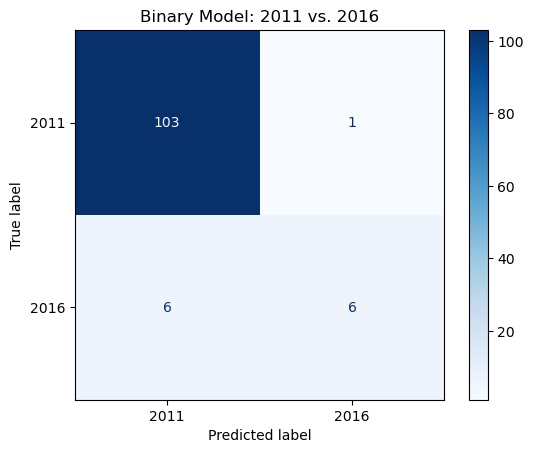

In [11]:
# Train binary classifier for 2011 vs. 2016

binary_train = y_train.isin([2011, 2016])
binary_test = y_test.isin([2011, 2016])

X_train_binary = X_train.loc[binary_train]
y_train_binary = y_train.loc[binary_train]

X_test_binary = X_test.loc[binary_test]
y_test_binary = y_test.loc[binary_test]

binary_model = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_vintage_description,
            lowercase=False,
            min_df=1,
            max_features=5000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"),
         metadata_cols)
    ])),
    ("classifier", LogisticRegression(
        max_iter=1500,
        random_state=42
    ))
])

binary_model.fit(X_train_binary, y_train_binary)

binary_predictions = binary_model.predict(X_test_binary)

print(classification_report(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    binary_predictions,
    labels=[2011, 2016],
    cmap="Blues"
)

plt.title("Binary Model: 2011 vs. 2016")
plt.show()

In [13]:
binary_comparison = X_test_binary.copy()

binary_comparison["actual_vintage"] = y_test_binary
binary_comparison["predicted_vintage"] = binary_predictions

binary_comparison["correct"] = (
    binary_comparison["actual_vintage"] ==
    binary_comparison["predicted_vintage"]
)

binary_summary = binary_comparison.groupby("actual_vintage").agg(
    total=("correct", "size"),
    correct=("correct", "sum"),
    accuracy=("correct", "mean")
)

display(binary_summary)

# Show incorrectly predicted wines
binary_errors = binary_comparison[
    ~binary_comparison["correct"]
]

display(binary_errors[
    ["actual_vintage", "predicted_vintage",
     "variety", "region_1", "description"]
].head(20))

binary_errors.to_csv("napa_binary_2011_2016.csv", index=False)

,total,correct,accuracy
actual_vintage,,,
2011,104,103,0.990385
2016,12,6,0.500000


,actual_vintage,predicted_vintage,variety,region_1,description
10820,2016,2011,Sauvignon Blanc,Napa Valley,"Reduced, with a pronounced aroma of oak, this ..."
11571,2016,2011,Viognier,Napa Valley,"A 100% varietal wine, this is dry and in balan..."
32586,2016,2011,Sauvignon Blanc,Oakville,Incorporating 30% of the variety in Musqué clo...
42102,2016,2011,Sauvignon Blanc,Oakville,"This is an oaky, woody and somewhat harsh whit..."
62326,2016,2011,Albariño,Napa Valley,This strengthens the argument that there's a p...
113612,2016,2011,Sauvignon Blanc,Calistoga,This wine has a grassy element that won't appe...
121714,2011,2016,Rosé,Napa Valley,"With a dark color and full body, this isn't ve..."


,Vintage,Full Model,Binary Model
0,2011,0.067308,0.990385
1,2016,0.000000,0.500000


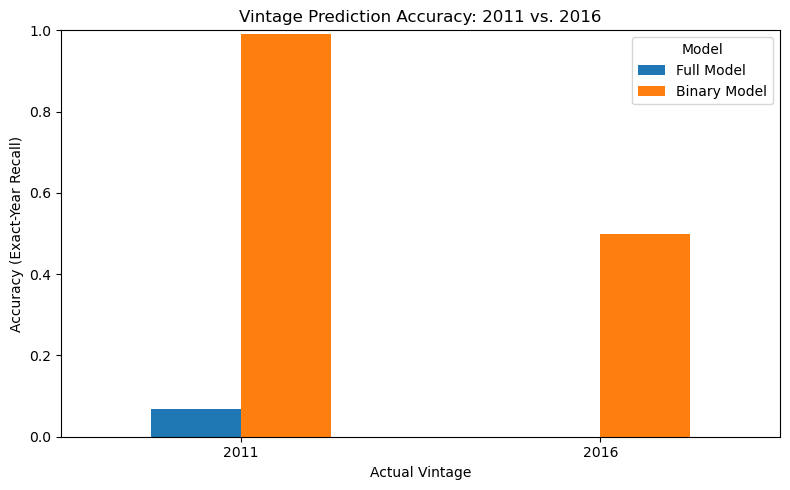

In [14]:
comparison = pd.DataFrame({
    "Vintage": [2011, 2016],
    "Full Model": [
        full_summary.loc[2011, "accuracy"],
        full_summary.loc[2016, "accuracy"]
    ],
    "Binary Model": [
        binary_summary.loc[2011, "accuracy"],
        binary_summary.loc[2016, "accuracy"]
    ]
})

display(comparison)

comparison.set_index("Vintage").plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Vintage Prediction Accuracy: 2011 vs. 2016")
plt.ylabel("Accuracy (Exact-Year Recall)")
plt.xlabel("Actual Vintage")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## What language distinguishes good and bad Napa vintages?

We first examine the pre-specified 2000 (bad) versus 2016 (good) contrast. Before interpreting words, we check reviewer overlap. If reviewers do not overlap across vintages, language can reflect author or period style rather than the wines. We then conduct a more defensible within-reviewer exploratory comparison of 2011 and 2016 using only reviews by Virginie Boone, the only reviewer represented in 2016.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

good_bad = (
    wine_df.loc[
        wine_df["region_2"].eq("Napa")
        & wine_df["wine vintage"].isin([2000, 2011, 2016]),
        ["title", "description", "wine vintage", "variety", "region_1", "taster_name"]
    ]
    .dropna(subset=["title", "wine vintage"])
    .drop_duplicates(subset="title")
    .copy()
)
good_bad["description"] = good_bad["description"].fillna("").astype(str)
good_bad = good_bad.loc[good_bad["description"].str.strip().ne("")].copy()
good_bad["taster_name"] = good_bad["taster_name"].fillna("Unknown")

unadjusted_reviewer_counts = pd.crosstab(
    good_bad.loc[good_bad["wine vintage"].isin([2000, 2016]), "taster_name"],
    good_bad.loc[good_bad["wine vintage"].isin([2000, 2016]), "wine vintage"],
)
print("2000 vs. 2016 reviewer counts:")
print(unadjusted_reviewer_counts.to_string())

# 2016 is reviewed only by Virginie Boone. Restricting both years to her reviews
# removes the strongest observable author confound, though it does not remove time effects.
matched_author_data = good_bad.loc[
    good_bad["taster_name"].eq("Virginie Boone")
    & good_bad["wine vintage"].isin([2011, 2016])
].copy()
for column in ["variety", "region_1"]:
    matched_author_data[column] = matched_author_data[column].fillna("Unknown").astype(str)

def clean_good_bad_text(text):
    text = re.sub(r"\b(?:18|19|20|21)\d{2}\b", " ", str(text)).lower()
    return re.sub(r"(?<!\d)(?:11|16)(?!\d)", " ", text)

sensory_terms = {
    "acidity", "acidic", "balanced", "blackberry", "crisp", "dry", "fresh", "herb",
    "leather", "oak", "pineapple", "soft", "tannins", "tropical", "blackberry",
}
X_language = matched_author_data[["description", "variety", "region_1"]]
y_language = matched_author_data["wine vintage"].astype(int)
language_model = Pipeline([
    ("features", ColumnTransformer([
        ("text", TfidfVectorizer(
            preprocessor=clean_good_bad_text, lowercase=False, stop_words="english",
            min_df=4, max_df=0.8, max_features=3000
        ), "description"),
        ("metadata", OneHotEncoder(handle_unknown="ignore"), ["variety", "region_1"]),
    ])),
    ("classifier", LogisticRegression(
        max_iter=1500, random_state=42, C=0.3, class_weight="balanced"
    )),
])
language_model.fit(X_language, y_language)
text_vectorizer = language_model.named_steps["features"].named_transformers_["text"]
terms = text_vectorizer.get_feature_names_out()
coefficients = language_model.named_steps["classifier"].coef_[0, :len(terms)]
classes = language_model.named_steps["classifier"].classes_
cleaned_matched_reviews = matched_author_data["description"].map(clean_good_bad_text)

good_bad_language = []
for vintage in classes:
    sign = 1 if vintage == classes[1] else -1
    ranked = sorted(
        [i for i, term in enumerate(terms) if term in sensory_terms],
        key=lambda i: sign * coefficients[i], reverse=True
    )
    kept = 0
    for index in ranked:
        term = terms[index]
        count = int(cleaned_matched_reviews.loc[y_language.eq(vintage)].str.contains(
            rf"\b{re.escape(term)}\b", regex=True
        ).sum())
        if count >= 4:
            good_bad_language.append({
                "Vintage": vintage, "Term": term,
                "Association coefficient": sign * coefficients[index],
                "Reviews containing term": count,
            })
            kept += 1
        if kept == 6:
            break

good_bad_language = pd.DataFrame(good_bad_language)
print(f"\nWithin-reviewer comparison: Virginie Boone, 2011 (n={(y_language == 2011).sum()}) vs. 2016 (n={(y_language == 2016).sum()})")
for vintage in [2011, 2016]:
    terms_for_year = good_bad_language.loc[good_bad_language["Vintage"].eq(vintage), "Term"].tolist()
    print(f"{vintage}: {', '.join(terms_for_year)}")


2000 vs. 2016 reviewer counts:
vintage        2000  2016
taster_name              
Unknown            51     0
Virginie Boone      0    68

Within-reviewer comparison: Virginie Boone, 2011 (n=246) vs. 2016 (n=68)
2011: tannins, soft, blackberry, herb, leather
2016: crisp, acidity, dry, pineapple, tropical, balanced


### Interpretation for Winetitude

The direct 2000-versus-2016 comparison cannot support a vintage-language conclusion: the retained 2000 reviews are almost entirely unattributed, while every retained 2016 review is by Virginie Boone. Any apparent difference could be reviewer identity or the evolution of review style over sixteen years.

The author-matched 2011-versus-2016 comparison is more informative but remains exploratory. Relative to 2011, 2016 reviews use more **crisp**, **acidity**, **dry**, **pineapple**, **tropical**, and **balanced** language. Relative to 2016, 2011 reviews use more **tannins**, **soft**, **blackberry**, **herb**, and **leather** language. The comparison includes 246 2011 and only 68 2016 reviews, so it is imbalanced and should be presented as descriptive evidence—not a claim that these words are caused by vintage quality.

For the presentation: describe this as a controlled reviewer-style exploration, explain why the 2000-versus-2016 result is confounded, and emphasize the more credible within-reviewer result.